# Análisis exploratorio de datos

Contentesta las siguientes preguntas escribiendo el código de Python necesario para encontrar las respuestas o producir las gráficas necesarias

---


In [28]:
# No mostrar advertencias
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/retailmax.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### 1. ¿Cuál es la distribución de edades de los clientes?
- **Objetivo**: Comprender la distribución de las edades en el conjunto de datos.
- **Respuesta esperada**: Un histograma de la columna Age.

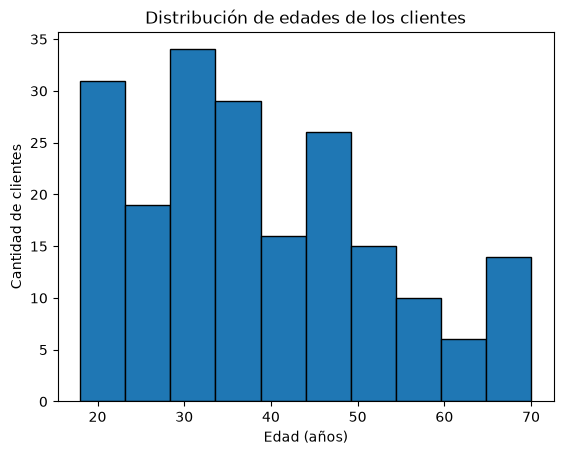

In [29]:
import matplotlib.pyplot as plt

plt.hist(df["Age"], bins=10, edgecolor="black")
plt.title("Distribución de edades de los clientes")
plt.xlabel("Edad (años)")
plt.ylabel("Cantidad de clientes")
plt.show()

### 2. ¿Existen diferencias significativas en los ingresos anuales entre hombres y mujeres?
- **Objetivo**: Comparar la distribución de ingresos anuales entre géneros.
- **Respuesta esperada**: Una gráfica de cajas (boxplot) que muestre la distribución de Annual Income (k$) por género.

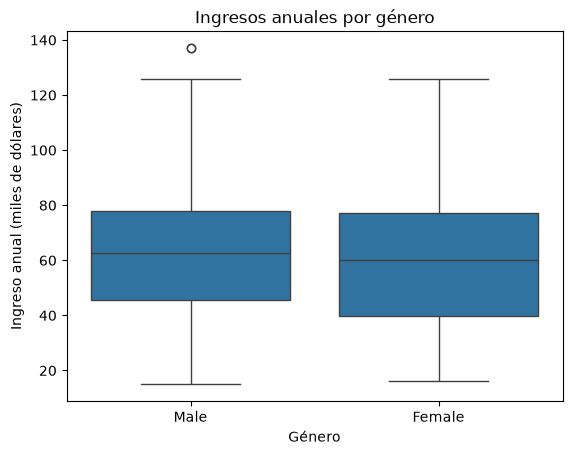

In [30]:
sns.boxplot(data=df, x="Gender", y="Annual Income (k$)")

plt.title("Ingresos anuales por género")
plt.xlabel("Género")
plt.ylabel("Ingreso anual (miles de dólares)")
plt.show()

### 3. ¿Cómo se distribuye la puntuación de gasto (Spending Score) entre los diferentes rangos de edad?
- **Objetivo**: Analizar la relación entre la edad y la puntuación de gasto.
- **Respuesta esperada**: Una gráfica de dispersión (scatter plot) o un gráfico de cajas que compare la Spending Score (1-100) con diferentes grupos de edad.

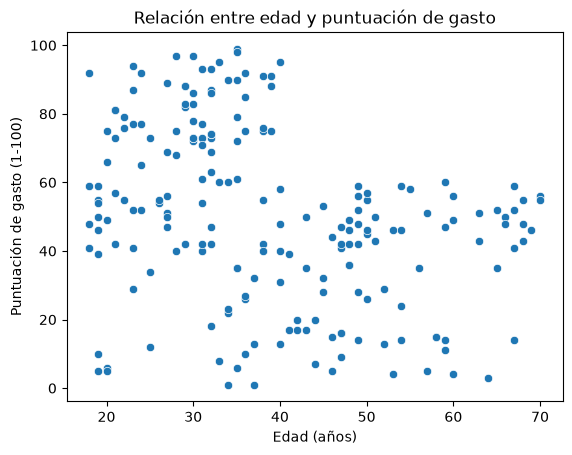

In [31]:
sns.scatterplot(data=df, x="Age", y="Spending Score (1-100)")

plt.title("Relación entre edad y puntuación de gasto")
plt.xlabel("Edad (años)")
plt.ylabel("Puntuación de gasto (1-100)")
plt.show()

### 4. ¿Cuál es la correlación entre el ingreso anual y la puntuación de gasto?
- **Objetivo**: Identificar si existe una relación lineal entre el ingreso y el gasto.
- **Respuesta esperada**: Una gráfica de dispersión y el cálculo del coeficiente de correlación entre Annual Income (k$) y Spending Score (1-100).

Correlación de Pearson: 0.010


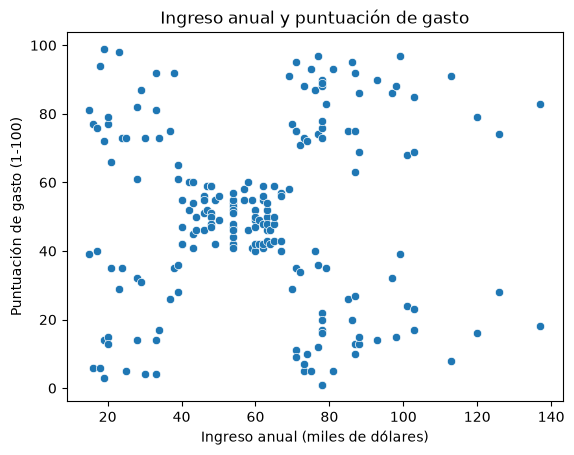

In [32]:
correlacion = df["Annual Income (k$)"].corr(
    df["Spending Score (1-100)"]
)
print(f"Correlación de Pearson: {correlacion:.3f}")

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)"
)
plt.title("Ingreso anual y puntuación de gasto")
plt.xlabel("Ingreso anual (miles de dólares)")
plt.ylabel("Puntuación de gasto (1-100)")
plt.show()

### 5. ¿Cómo varía la puntuación de gasto en diferentes grupos de ingresos anuales?
- **Objetivo**: Examinar cómo los clientes en diferentes rangos de ingresos se comportan en términos de gasto.
- **Respuesta esperada**: Una gráfica de cajas o de violín que muestre la Spending Score (1-100) para diferentes rangos de Annual Income (k$).

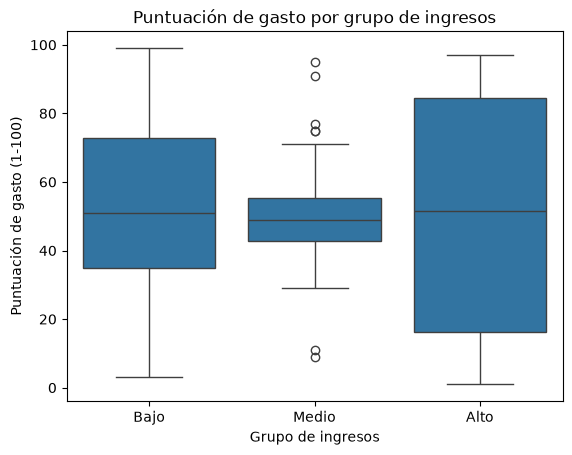

In [33]:
df["Grupo de ingresos"] = pd.qcut(
    df["Annual Income (k$)"],
    q=3,
    labels=["Bajo", "Medio", "Alto"]
)

sns.boxplot(
    data=df,
    x="Grupo de ingresos",
    y="Spending Score (1-100)"
)
plt.title("Puntuación de gasto por grupo de ingresos")
plt.xlabel("Grupo de ingresos")
plt.ylabel("Puntuación de gasto (1-100)")
plt.show()

### 6. ¿Cuál es la proporción de clientes por género?
- **Objetivo**: Determinar el balance de género en el conjunto de datos.
- **Respuesta esperada**: Una gráfica de barras o un gráfico de pastel que muestre la proporción de hombres y mujeres.

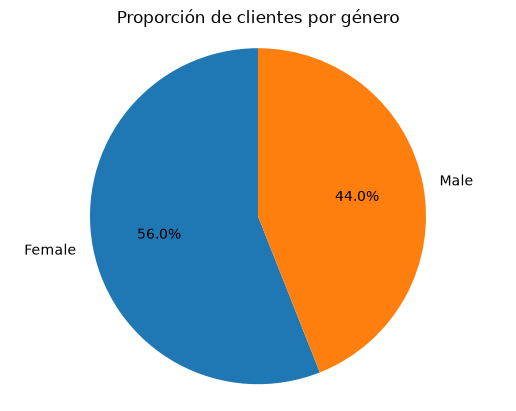

In [34]:
conteo = df["Gender"].value_counts()

conteo.plot.pie(autopct="%1.1f%%", startangle=90)
plt.title("Proporción de clientes por género")
plt.ylabel("")
plt.axis("equal")
plt.show()

### 7. ¿Qué grupos de edad gastan más en promedio?
- **Objetivo**: Identificar los grupos de edad que tienen una mayor puntuación de gasto en promedio.
- **Respuesta esperada**: Una gráfica de barras que compare la puntuación de gasto promedio entre diferentes grupos de edad.

Grupo de edad
Hasta 25    54.95
26-35       64.45
36-45       44.83
46-55       36.70
56 o más    38.38
Name: Spending Score (1-100), dtype: float64


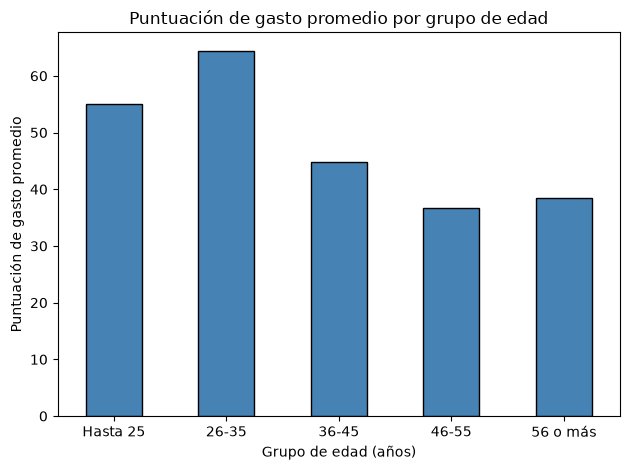

In [35]:
df["Grupo de edad"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 55, float("inf")],
    labels=["Hasta 25", "26-35", "36-45", "46-55", "56 o más"]
)

promedios = df.groupby(
    "Grupo de edad", observed=True
)["Spending Score (1-100)"].mean()

print(promedios.round(2))

promedios.plot.bar(color="steelblue", edgecolor="black")
plt.title("Puntuación de gasto promedio por grupo de edad")
plt.xlabel("Grupo de edad (años)")
plt.ylabel("Puntuación de gasto promedio")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 8. ¿Hay alguna relación entre la edad y el ingreso anual de los clientes?
- **Objetivo**: Explorar si hay una tendencia entre la edad de los clientes y sus ingresos.
- **Respuesta esperada**: Una gráfica de dispersión que muestre la relación entre Age y Annual Income (k$).

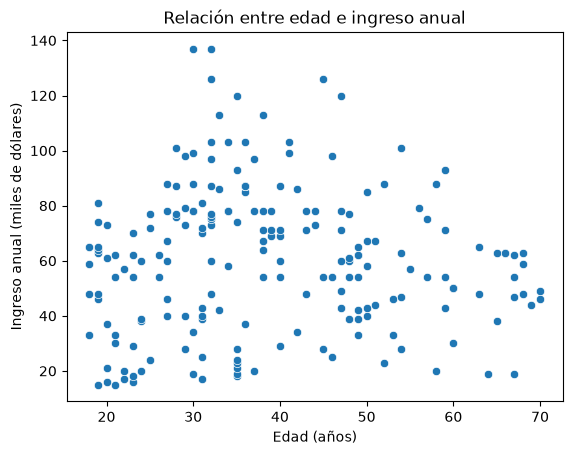

In [36]:
sns.scatterplot(data=df, x="Age", y="Annual Income (k$)")

plt.title("Relación entre edad e ingreso anual")
plt.xlabel("Edad (años)")
plt.ylabel("Ingreso anual (miles de dólares)")
plt.show()

### 9. ¿Cuál es la distribución conjunta de la edad y el ingreso anual?
- **Objetivo**: Entender cómo se distribuyen estas dos variables en conjunto.
- **Respuesta esperada**: Una gráfica de dispersión con una densidad de puntos o un gráfico de hexágonos que muestre la distribución conjunta de Age y Annual Income (k$).

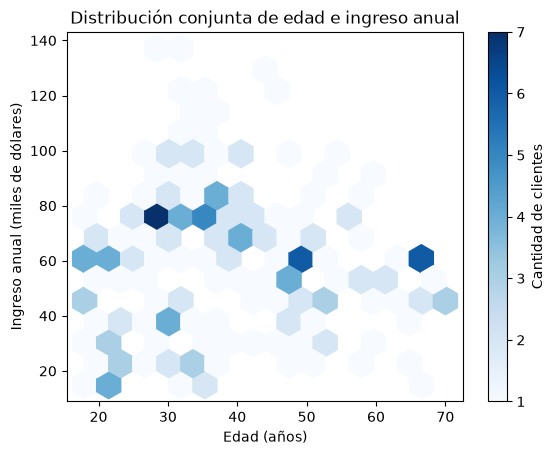

In [37]:
plt.hexbin(
    df["Age"],
    df["Annual Income (k$)"],
    gridsize=15,
    cmap="Blues",
    mincnt=1
)

plt.colorbar(label="Cantidad de clientes")
plt.title("Distribución conjunta de edad e ingreso anual")
plt.xlabel("Edad (años)")
plt.ylabel("Ingreso anual (miles de dólares)")
plt.show()

### 10. ¿Cómo se distribuyen los clientes en función de la puntuación de gasto y el género?
- **Objetivo**: Analizar la relación entre la puntuación de gasto y el género.
- **Respuesta esperada**: Una gráfica de dispersión o un gráfico de violín que muestre la Spending Score (1-100) separada por género.

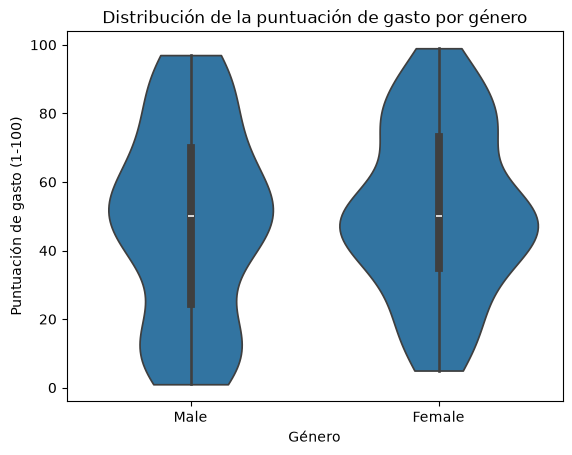

In [38]:
sns.violinplot(
    data=df,
    x="Gender",
    y="Spending Score (1-100)",
    inner="box",
    cut=0
)

plt.title("Distribución de la puntuación de gasto por género")
plt.xlabel("Género")
plt.ylabel("Puntuación de gasto (1-100)")
plt.show()